In [2]:
import squidpy as sq

adata = sq.datasets.visium_hne_adata()
print(adata)
print(adata.obs.columns.tolist())
print(adata.obsm.keys())

/Users/muradyan.e/wut/bioinform/.venv/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound
/Users/muradyan.e/wut/bioinform/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


AnnData object with n_obs × n_vars = 2688 × 18078
    obs: 'in_tissue', 'array_row', 'array_col', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_counts', 'leiden', 'cluster'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'cluster_colors', 'hvg', 'leiden', 'leiden_colors', 'neighbors', 'pca', 'rank_genes_groups', 'spatial', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'
['in_tissue', 'array_row', 'array_col', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_c

In [4]:
import squidpy as sq

import scanpy as sc
import pandas as pd
import numpy as np

adata = sc.read_h5ad(
    "data/anndata/visium_hne_adata.h5ad"
)

print(adata)
print("\nObservation columns:")
print(adata.obs.columns.tolist())

for col in ["in_tissue", "leiden", "cluster"]:
    if col in adata.obs.columns:
        print(f"\n--- {col} ---")
        print("Unique values:", adata.obs[col].nunique())
        print(adata.obs[col].value_counts(dropna=False).head(20))

print("\nSpatial coordinates:", adata.obsm["spatial"].shape)
print("Expression matrix:", adata.X.shape)
print("Unstructured metadata keys:", list(adata.uns.keys()))

if "cluster" in adata.obs:
    print("\nCluster categories:")
    print(adata.obs["cluster"].cat.categories
          if isinstance(adata.obs["cluster"].dtype, pd.CategoricalDtype)
          else adata.obs["cluster"].unique())

AnnData object with n_obs × n_vars = 2688 × 18078
    obs: 'in_tissue', 'array_row', 'array_col', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_counts', 'leiden', 'cluster'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'cluster_colors', 'hvg', 'leiden', 'leiden_colors', 'neighbors', 'pca', 'rank_genes_groups', 'spatial', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

Observation columns:
['in_tissue', 'array_row', 'array_col', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_c

In [2]:
import scanpy as sc
import numpy as np
import pandas as pd

adata = sc.read_h5ad(
    "data/anndata/visium_hne_adata.h5ad"
)

# Keep only spots inside the tissue
adata = adata[adata.obs["in_tissue"] == 1].copy()

# Save the anatomical labels as ground truth
adata.obs["ground_truth"] = (
    adata.obs["cluster"].astype("category")
)

print("Dataset:", adata)
print("Ground-truth regions:",
      adata.obs["ground_truth"].nunique())
print(adata.obs["ground_truth"].value_counts())

print("\nExpression matrix type:", type(adata.X))
print("Spatial coordinates:", adata.obsm["spatial"].shape)
print("Existing PCA:", adata.obsm["X_pca"].shape)

Dataset: AnnData object with n_obs × n_vars = 2688 × 18078
    obs: 'in_tissue', 'array_row', 'array_col', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_counts', 'leiden', 'cluster', 'ground_truth'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'cluster_colors', 'hvg', 'leiden', 'leiden_colors', 'neighbors', 'pca', 'rank_genes_groups', 'spatial', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'
Ground-truth regions: 15
ground_truth
Cortex_1                         284
Thalamus_1        

In [3]:
print("Dataset metadata:")
print(adata.uns.get("description", "No description field"))

print("\nCluster metadata:")
print(adata.uns.get("cluster", "No cluster metadata"))

print("\nLeiden metadata:")
print(adata.uns.get("leiden", "No Leiden metadata"))

Dataset metadata:
No description field

Cluster metadata:
No cluster metadata

Leiden metadata:
{'params': {'n_iterations': np.int64(-1), 'random_state': np.int64(0), 'resolution': np.float64(0.7)}}


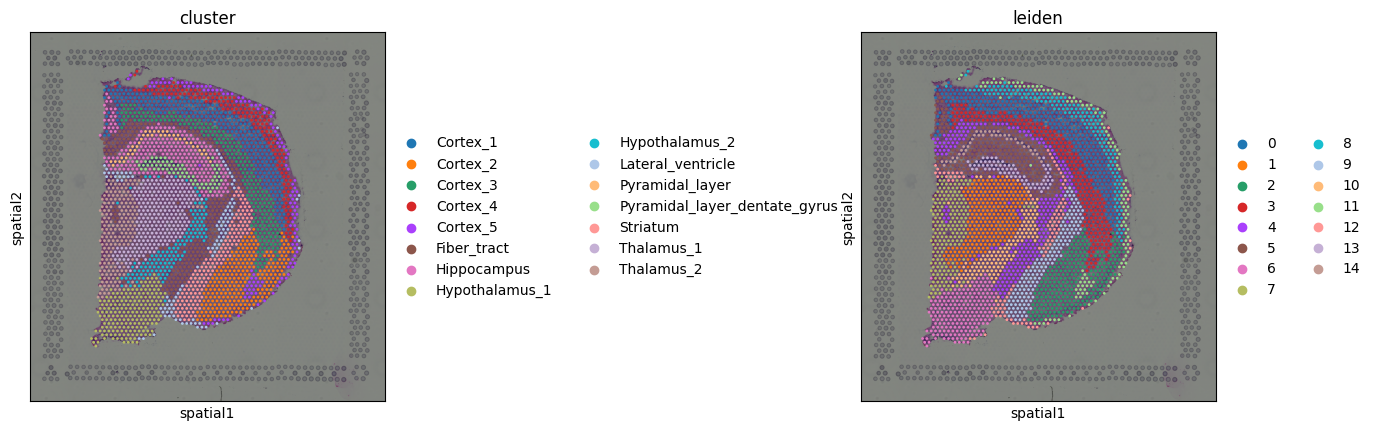

In [4]:
import squidpy as sq

sq.pl.spatial_scatter(
    adata,
    color=["cluster", "leiden"],
    wspace=0.4
)

## Our clustering heads on this section

Apply the three clustering heads used in the thesis (KMeans, resolution-matched Louvain, and ClusterPFN)
to this single mouse-brain section, each given the ground-truth number of regions `k`, and score them
against the anatomical `ground_truth` with ARI and NMI. The shared representation is the existing 50-D PCA.

One caveat specific to this dataset: it has 15 regions, but the `pfn_hard_5D` checkpoint was trained with
`buckets_size = 10`, so ClusterPFN can emit at most 10 clusters here. Its conditioning `k` is therefore
capped at 10, which puts it at a structural disadvantage on a 15-region section (unlike the 5 to 7 layer
DLPFC data it was used for).


In [ ]:
import torch
import numpy as np
import scanpy as sc
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

import clusterpfn.transformer as transformer

device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")

PFN_MODEL_PATH = "models/pfn_hard_5D.pt"
PFN_IN_FEATURES = 5
PFN_BUCKETS = 10         

gt = adata.obs["ground_truth"].astype("category")
k = gt.cat.categories.size
rep = np.asarray(adata.obsm["X_pca"])


def evaluate(truth, pred):
    return adjusted_rand_score(truth, pred), normalized_mutual_info_score(truth, pred)


def cluster_kmeans(X, k, seed=42):
    Xs = StandardScaler().fit_transform(np.asarray(X))
    return KMeans(n_clusters=k, random_state=seed, n_init=20).fit_predict(Xs)


def cluster_louvain(X, k, seed=42, n_neighbors=15, max_iter=25):
    """Louvain on a kNN graph; binary-search the resolution to hit k communities."""
    ad = sc.AnnData(StandardScaler().fit_transform(np.asarray(X)).astype(np.float32))
    sc.pp.neighbors(ad, n_neighbors=n_neighbors, use_rep="X", random_state=seed)
    lo, hi, best = 0.1, 3.0, None
    for _ in range(max_iter):
        res = (lo + hi) / 2
        sc.tl.louvain(ad, resolution=res, random_state=seed)
        labels = ad.obs["louvain"].astype(int).to_numpy()
        found = len(np.unique(labels))
        if found == k:
            return labels
        best = labels
        if found < k:
            lo = res
        else:
            hi = res
    return best


def prepare_for_pfn(X, in_features=PFN_IN_FEATURES):
    Xs = StandardScaler().fit_transform(np.asarray(X))
    if Xs.shape[1] > in_features:
        Xs = PCA(n_components=in_features, random_state=42).fit_transform(Xs)
    return MinMaxScaler().fit_transform(Xs).astype(np.float32)


def load_pfn():
    model = transformer.Transformer(256, 4, 512, 4,
                                    in_features=PFN_IN_FEATURES, buckets_size=PFN_BUCKETS).to(device)
    ck = torch.load(PFN_MODEL_PATH, map_location=device)
    model.load_state_dict(ck["model_state_dict"])
    model.eval()
    return model


def run_pfn(model, X, k):
    t = torch.tensor(X, dtype=torch.float32, device=device).unsqueeze(1)  # (S, 1, F)
    num = torch.full((t.shape[0] + 1, 1), int(k), dtype=torch.long, device=device)
    with torch.no_grad():
        out, _ = model(t, num)
    return out.squeeze(1).argmax(dim=-1).cpu().numpy()


pfn = load_pfn()
k_pfn = min(k, PFN_BUCKETS)   # the checkpoint cannot be conditioned above its bucket count

adata.obs["kmeans"] = cluster_kmeans(rep, k).astype(str)
adata.obs["louvain"] = cluster_louvain(rep, k).astype(str)
adata.obs["clusterpfn"] = run_pfn(pfn, prepare_for_pfn(rep), k_pfn).astype(str)

print(f"Ground-truth regions: {k}  (ClusterPFN conditioned on k={k_pfn})\n")
for name in ["kmeans", "louvain", "clusterpfn"]:
    adata.obs[name] = adata.obs[name].astype("category")
    ari, nmi = evaluate(gt.astype(str), adata.obs[name])
    print(f"{name:11s} | clusters={adata.obs[name].nunique():2d} | ARI={ari:.3f} | NMI={nmi:.3f}")

/Users/muradyan.e/wut/bioinform/.venv/lib/python3.11/site-packages/torch/nn/modules/transformer.py:144: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.encoder = TransformerEncoder(


Ground-truth regions: 15  (ClusterPFN conditioned on k=10)

kmeans      | clusters=15 | ARI=0.602 | NMI=0.760
louvain     | clusters=15 | ARI=0.589 | NMI=0.725
clusterpfn  | clusters= 2 | ARI=0.003 | NMI=0.025


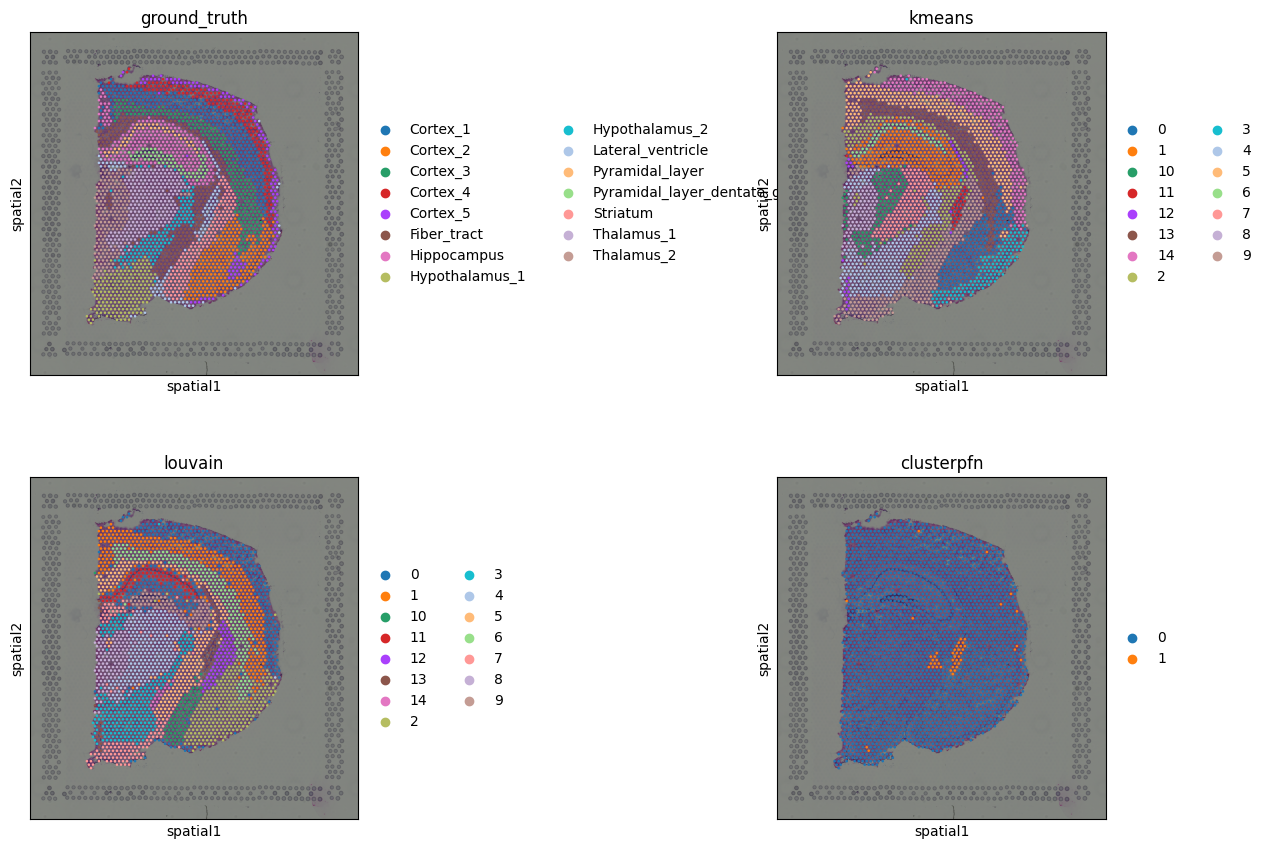

In [6]:
import squidpy as sq

sq.pl.spatial_scatter(
    adata,
    color=["ground_truth", "kmeans", "louvain", "clusterpfn"],
    ncols=2,
    wspace=0.3,
    hspace=0.3,
)

## Embedding and fusion pipelines on this section

Run the full Experiment C pipeline on this mouse-brain slide: compute the three spatial encoders
(STAGATE, GraphST, SpaGCN) with the same settings used for DLPFC, cache them, then cluster each embedding
and the STAGATE $\oplus$ SpaGCN late fusion with KMeans, Leiden, and ClusterPFN.

Notes:
- The encoders are not cached for this dataset, so they are computed here. STAGATE needs the TensorFlow 1.x
  graph API, so if the kernel misbehaves, restart it and run this section first.
- Encoder hyperparameters match `embedding_generation.ipynb` (3000 HVGs, STAGATE k=6, GraphST k=3, SpaGCN p=0.5).
- ClusterPFN stays capped at 10 clusters (`buckets_size=10`), so on this 15-region slide it is conditioned on k=10.


In [2]:
# Encoders need TF1 eager disabled BEFORE importing STAGATE.
import tensorflow as tf
tf.compat.v1.disable_eager_execution()

import STAGATE
import GraphST
from GraphST.GraphST import GraphST as GraphSTModel
import SpaGCN

import scipy.sparse as sp
if not hasattr(sp.csr_matrix, "A"):
    sp.csr_matrix.A = property(lambda self: self.toarray())
if not hasattr(sp.csc_matrix, "A"):
    sp.csc_matrix.A = property(lambda self: self.toarray())

import numpy as np
import scanpy as sc
import torch


def prepare_expression(ad, n_hvg=3000):
    ad = ad.copy()
    sc.pp.highly_variable_genes(ad, n_top_genes=n_hvg, flavor="seurat")
    return ad[:, ad.var["highly_variable"]].copy()


def run_stagate(ad, k=6):
    ad = prepare_expression(ad)
    STAGATE.Cal_Spatial_Net(ad, k_cutoff=k, model="KNN", verbose=False)
    STAGATE.train_STAGATE(ad, hidden_dims=[512, 30], alpha=0, random_seed=42, verbose=False)
    return np.asarray(ad.obsm["STAGATE"])


def run_graphst(ad):
    ad = prepare_expression(ad)
    GraphST.construct_interaction(ad, n_neighbors=3)
    model = GraphSTModel(ad, device=torch.device("cpu"), learning_rate=0.001, weight_decay=0.0,
                         epochs=10, dim_input=3000, dim_output=64, random_seed=42,  # epochs=10 matches the DLPFC run
                         alpha=10, beta=1, theta=0.1, lamda1=10, lamda2=1,
                         deconvolution=False, datatype="10X")
    model.train()
    return model.hiden_feat.detach().cpu().numpy()


def run_spagcn(ad):
    ad = ad.copy()
    coords = np.asarray(ad.obsm["spatial"])
    adj = SpaGCN.calculate_adj_matrix(x=coords[:, 0].tolist(), y=coords[:, 1].tolist(), histology=False)
    l = SpaGCN.search_l(0.5, adj)
    if l is None:
        raise RuntimeError("SpaGCN search_l failed.")
    clf = SpaGCN.SpaGCN()
    clf.set_l(l)
    clf.train(ad, adj, num_pcs=50, init="louvain", res=0.4, tol=1e-3)  # SpaGCN's own internal init
    z, _ = clf.model.predict(clf.embed, clf.adj_exp)
    return z.detach().cpu().numpy()

/Users/muradyan.e/wut/bioinform/.venv/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound
/Users/muradyan.e/wut/bioinform/.venv/lib/python3.11/site-packages/anndata/__init__.py:70: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  return module_get_attr_redirect(attr_name, deprecated_mapping=_DEPRECATED)
/Users/muradyan.e/wut/bioinform/.venv/lib/python3.11/site-packages/anndata/__init__.py:70: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  return module_get_attr_redirect(attr_name, deprecated_mapping=_DEPRECATED)
/Users/muradyan.e/wut/bioinform/.venv/lib/python3.11/site-pack

In [3]:
import os

SEC = "visium_hne"
EMB_DIR = "experiment_test_embeddings"
os.makedirs(EMB_DIR, exist_ok=True)

# Fresh load so the encoders get a clean, in-tissue AnnData with the ground-truth labels.
base = sc.read_h5ad("data/anndata/visium_hne_adata.h5ad")
base = base[base.obs["in_tissue"] == 1].copy()
base.obs["ground_truth"] = base.obs["cluster"].astype("category")

ENCODERS = {"STAGATE": run_stagate, "GraphST": run_graphst, "SpaGCN": run_spagcn}
emb = {}
for method, fn in ENCODERS.items():
    path = f"{EMB_DIR}/{SEC}_{method}_embedding.npy"
    if os.path.exists(path):
        emb[method] = np.load(path)
        print(f"{method}: loaded cache {emb[method].shape}")
    else:
        print(f"{method}: computing ...", flush=True)
        e = fn(base)
        np.save(path, e)
        emb[method] = e
        print(f"{method}: saved {e.shape}")

STAGATE: loaded cache (2688, 30)
GraphST: loaded cache (2688, 64)
SpaGCN: loaded cache (2688, 50)


In [8]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
import pandas as pd
import clusterpfn.transformer as transformer

device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if torch.backends.mps.is_available() else "cpu")
PFN_MODEL_PATH, PFN_IN_FEATURES, PFN_BUCKETS = "models/pfn_hard_5D.pt", 5, 10

gt = base.obs["ground_truth"].astype(str)
k = gt.nunique()


def fuse(embs):
    return np.concatenate([StandardScaler().fit_transform(np.asarray(e)) for e in embs], axis=1)


def cluster_kmeans(X, k, seed=42):
    return KMeans(n_clusters=k, random_state=seed, n_init=20).fit_predict(
        StandardScaler().fit_transform(np.asarray(X)))


def _cluster_graph(X, k, method, seed=42, n_neighbors=15, max_iter=25):
    """Leiden or Louvain on a kNN graph; binary-search the resolution to hit k communities."""
    ad = sc.AnnData(StandardScaler().fit_transform(np.asarray(X)).astype(np.float32))
    sc.pp.neighbors(ad, n_neighbors=n_neighbors, use_rep="X", random_state=seed)
    lo, hi, best = 0.1, 3.0, None
    for _ in range(max_iter):
        res = (lo + hi) / 2
        if method == "leiden":
            sc.tl.leiden(ad, resolution=res, random_state=seed,
                         flavor="igraph", n_iterations=2, directed=False)
        else:
            sc.tl.louvain(ad, resolution=res, random_state=seed)
        labels = ad.obs[method].astype(int).to_numpy()
        found = len(np.unique(labels))
        if found == k:
            return labels
        best = labels
        lo, hi = (res, hi) if found < k else (lo, res)
    return best


def cluster_leiden(X, k, **kw):
    return _cluster_graph(X, k, "leiden", **kw)


def cluster_louvain(X, k, **kw):
    return _cluster_graph(X, k, "louvain", **kw)


def prepare_for_pfn(X):
    Xs = StandardScaler().fit_transform(np.asarray(X))
    if Xs.shape[1] > PFN_IN_FEATURES:
        Xs = PCA(n_components=PFN_IN_FEATURES, random_state=42).fit_transform(Xs)
    return MinMaxScaler().fit_transform(Xs).astype(np.float32)


def load_pfn():
    m = transformer.Transformer(256, 4, 512, 4, in_features=PFN_IN_FEATURES, buckets_size=PFN_BUCKETS).to(device)
    m.load_state_dict(torch.load(PFN_MODEL_PATH, map_location=device)["model_state_dict"])
    m.eval()
    return m


def run_pfn(model, X, k):
    t = torch.tensor(X, dtype=torch.float32, device=device).unsqueeze(1)
    num = torch.full((t.shape[0] + 1, 1), int(k), dtype=torch.long, device=device)
    with torch.no_grad():
        out, _ = model(t, num)
    return out.squeeze(1).argmax(dim=-1).cpu().numpy()


pfn = load_pfn()
k_pfn = min(k, PFN_BUCKETS)   # checkpoint cannot be conditioned above its bucket count

reps = {**emb, "Fused": fuse([emb["STAGATE"], emb["SpaGCN"]])}
rows = []
for name, e in reps.items():
    km = cluster_kmeans(e, k)
    lei = cluster_leiden(e, k)
    lou = cluster_louvain(e, k)
    pf = run_pfn(pfn, prepare_for_pfn(e), k_pfn)
    rows.append({
        "representation": name,
        "KMeans_ARI": adjusted_rand_score(gt, km), "KMeans_NMI": normalized_mutual_info_score(gt, km),
        "Leiden_ARI": adjusted_rand_score(gt, lei), "Leiden_NMI": normalized_mutual_info_score(gt, lei),
        "Louvain_ARI": adjusted_rand_score(gt, lou), "Louvain_NMI": normalized_mutual_info_score(gt, lou),
        "PFN_ARI": adjusted_rand_score(gt, pf), "PFN_NMI": normalized_mutual_info_score(gt, pf),
    })

res_df = pd.DataFrame(rows).set_index("representation").round(3)
print(f"Section {SEC}: {k} regions (ClusterPFN conditioned on k={k_pfn})\n")
print(res_df.to_string())
res_df

/Users/muradyan.e/wut/bioinform/.venv/lib/python3.11/site-packages/torch/nn/modules/transformer.py:144: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.encoder = TransformerEncoder(


Section visium_hne: 15 regions (ClusterPFN conditioned on k=10)

                KMeans_ARI  KMeans_NMI  Leiden_ARI  Leiden_NMI  Louvain_ARI  Louvain_NMI  PFN_ARI  PFN_NMI
representation                                                                                            
STAGATE              0.567       0.704       0.568       0.707        0.527        0.700    0.266    0.449
GraphST              0.541       0.669       0.572       0.686        0.525        0.662    0.140    0.299
SpaGCN               0.565       0.725       0.571       0.728        0.561        0.724    0.411    0.572
Fused                0.692       0.781       0.647       0.763        0.689        0.791    0.338    0.520


,KMeans_ARI,KMeans_NMI,Leiden_ARI,Leiden_NMI,Louvain_ARI,Louvain_NMI,PFN_ARI,PFN_NMI
representation,,,,,,,,
STAGATE,0.567,0.704,0.568,0.707,0.527,0.700,0.266,0.449
GraphST,0.541,0.669,0.572,0.686,0.525,0.662,0.140,0.299
SpaGCN,0.565,0.725,0.571,0.728,0.561,0.724,0.411,0.572
Fused,0.692,0.781,0.647,0.763,0.689,0.791,0.338,0.520


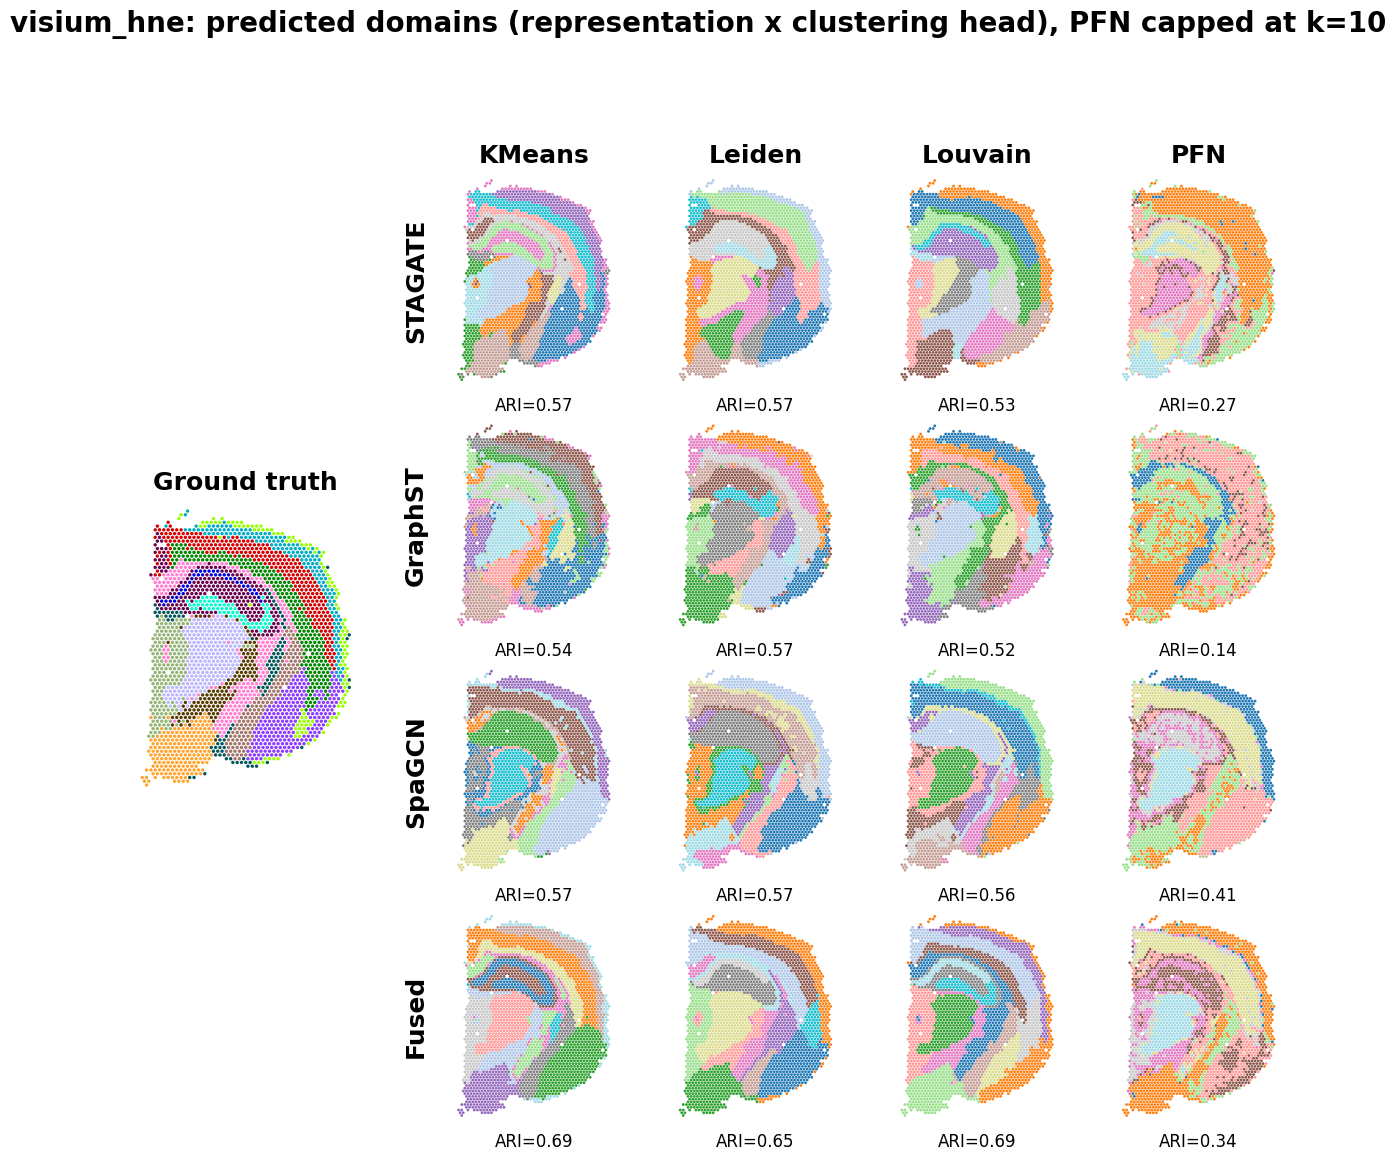

Saved -> experiment_test_plots/vis_visium_hne.png


In [10]:
import os
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.colors import ListedColormap
import colorcet as cc

os.makedirs("experiment_test_plots", exist_ok=True)

HEADS_VIS = ["KMeans", "Leiden", "Louvain", "PFN"]
coords = np.asarray(base.obsm["spatial"])
gt_codes = gt.astype("category").cat.codes.to_numpy()

TITLE_FS, LABEL_FS, SUP_FS, ARI_FS = 18, 18, 20, 12


def predict(emb_, head):
    if head == "KMeans":
        return cluster_kmeans(emb_, k)
    if head == "Leiden":
        return cluster_leiden(emb_, k, max_iter=12)  # lighter search for the figure
    if head == "Louvain":
        return cluster_louvain(emb_, k, max_iter=12)
    return run_pfn(pfn, prepare_for_pfn(emb_), k_pfn)


def _scatter(ax, labels, ground_truth=False):
    # Ground truth uses the saturated glasbey palette; predictions keep the default tab20.
    if ground_truth:
        uniq = np.unique(labels)
        idx = np.searchsorted(uniq, labels)
        cmap = ListedColormap(cc.glasbey[:len(uniq)])
        ax.scatter(coords[:, 0], coords[:, 1], c=idx, cmap=cmap, s=6, linewidths=0)
    else:
        ax.scatter(coords[:, 0], coords[:, 1], c=labels, cmap="tab20", s=4, linewidths=0)
    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.axis("off")


names = list(reps)
nrows, ncols = len(names), len(HEADS_VIS)
fig = plt.figure(figsize=(2.9 * (ncols + 1) + 0.6, 3.1 * nrows))
gs = GridSpec(nrows, ncols + 2, figure=fig,
              width_ratios=[1.1, 0.2] + [1] * ncols, wspace=0.08, hspace=0.12)

ax_gt = fig.add_subplot(gs[:, 0])
_scatter(ax_gt, gt_codes, ground_truth=True)
ax_gt.set_title("Ground truth", fontsize=TITLE_FS, fontweight="bold")

for i, name in enumerate(names):
    for j, head in enumerate(HEADS_VIS):
        ax = fig.add_subplot(gs[i, j + 2])
        pred = predict(reps[name], head)
        ari = adjusted_rand_score(gt, pred)
        _scatter(ax, pred)
        ax.text(0.5, -0.03, f"ARI={ari:.2f}", transform=ax.transAxes,
                ha="center", va="top", fontsize=ARI_FS)
        if i == 0:
            ax.set_title(head, fontsize=TITLE_FS, fontweight="bold")
        if j == 0:
            ax.text(-0.14, 0.5, name, transform=ax.transAxes, rotation=90,
                    ha="right", va="center", fontsize=LABEL_FS, fontweight="bold")

fig.suptitle(f"{SEC}: predicted domains (representation x clustering head), PFN capped at k={k_pfn}",
             fontsize=SUP_FS, fontweight="bold", y=1.01)
fig.savefig(f"experiment_test_plots/vis_{SEC}.png", dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved -> experiment_test_plots/vis_{SEC}.png")

In [5]:
# Persist this section's ARI/NMI (res_df already holds them per representation x head).
os.makedirs("results", exist_ok=True)

# Readable per-representation table.
res_df.to_csv(f"results/{SEC}_results_by_representation.csv")

# One-row wide table matching the DLPFC pipelines ({rep}_{head}_ARI/NMI columns).
wide = {"section": SEC, "n_clusters": k, "pfn_k": k_pfn}
for r in rows:
    rep_name = r["representation"]
    for col, val in r.items():
        if col != "representation":
            wide[f"{rep_name}_{col}"] = round(float(val), 4)
wide_df = pd.DataFrame([wide])
wide_df.to_csv(f"results/{SEC}_results.csv", index=False)

print(f"Saved -> results/{SEC}_results_by_representation.csv")
print(f"Saved -> results/{SEC}_results.csv")
res_df

Saved -> results/visium_hne_results_by_representation.csv
Saved -> results/visium_hne_results.csv


,KMeans_ARI,KMeans_NMI,Leiden_ARI,Leiden_NMI,PFN_ARI,PFN_NMI
representation,,,,,,
STAGATE,0.567,0.704,0.568,0.707,0.266,0.449
GraphST,0.541,0.669,0.572,0.686,0.140,0.299
SpaGCN,0.565,0.725,0.571,0.728,0.411,0.572
Fused,0.692,0.781,0.647,0.763,0.338,0.520


## Second squidpy dataset: visium_fluo

`squidpy.datasets` also provides `visium_fluo_adata`, a second 10x Visium mouse-brain section (fluorescence),
with the same structure as the H&E slide: anatomical `cluster` labels (15 regions), `in_tissue`, `spatial`,
and `X_pca`. (Other annotated options include `slideseqv2`, `merfish`, and `seqfish`, but those are different
platforms; keeping both examples on Visium makes the comparison apples-to-apples.)



In [ ]:
SQUIDPY_SECTIONS = {
    "visium_hne": "data/anndata/visium_hne_adata.h5ad",
    "visium_fluo": "data/anndata/visium_fluo_adata.h5ad",
}


def run_section(sec, path):
    ad = sc.read_h5ad(path)
    ad = ad[ad.obs["in_tissue"] == 1].copy()
    gt_ = ad.obs["cluster"].astype(str)
    k_ = gt_.nunique()
    k_pfn_ = min(k_, PFN_BUCKETS)

    embs = {}
    for method, fn in ENCODERS.items():
        p = f"{EMB_DIR}/{sec}_{method}_embedding.npy"
        if os.path.exists(p):
            embs[method] = np.load(p)
        else:
            print(f"{sec} {method}: computing ...", flush=True)
            e_ = fn(ad)
            np.save(p, e_)
            embs[method] = e_

    reps_ = {**embs, "Fused": fuse([embs["STAGATE"], embs["SpaGCN"]])}
    out = []
    for name, e_ in reps_.items():
        km_ = cluster_kmeans(e_, k_)
        lei_ = cluster_leiden(e_, k_)
        lou_ = cluster_louvain(e_, k_)
        pf_ = run_pfn(pfn, prepare_for_pfn(e_), k_pfn_)
        out.append({
            "section": sec, "representation": name, "n_clusters": k_, "pfn_k": k_pfn_,
            "KMeans_ARI": adjusted_rand_score(gt_, km_), "KMeans_NMI": normalized_mutual_info_score(gt_, km_),
            "Leiden_ARI": adjusted_rand_score(gt_, lei_), "Leiden_NMI": normalized_mutual_info_score(gt_, lei_),
            "Louvain_ARI": adjusted_rand_score(gt_, lou_), "Louvain_NMI": normalized_mutual_info_score(gt_, lou_),
            "PFN_ARI": adjusted_rand_score(gt_, pf_), "PFN_NMI": normalized_mutual_info_score(gt_, pf_),
        })
    return out


all_rows = []
for s, p in SQUIDPY_SECTIONS.items():
    all_rows += run_section(s, p)

combined = pd.DataFrame(all_rows)
combined.to_csv("results/squidpy_results.csv", index=False)

view = combined.set_index(["section", "representation"])[
    ["KMeans_ARI", "Leiden_ARI", "Louvain_ARI", "PFN_ARI",
     "KMeans_NMI", "Leiden_NMI", "Louvain_NMI", "PFN_NMI"]].round(3)
print("Saved -> results/squidpy_results.csv\n")
print(view.to_string())
view

Saved -> results/squidpy_results.csv

                            KMeans_ARI  Leiden_ARI  Louvain_ARI  PFN_ARI  KMeans_NMI  Leiden_NMI  Louvain_NMI  PFN_NMI
section     representation                                                                                            
visium_hne  STAGATE              0.567       0.568        0.527    0.266       0.704       0.707        0.700    0.449
            GraphST              0.541       0.572        0.525    0.140       0.669       0.686        0.662    0.299
            SpaGCN               0.565       0.571        0.561    0.411       0.725       0.728        0.724    0.572
            Fused                0.692       0.647        0.689    0.338       0.781       0.763        0.791    0.520
visium_fluo STAGATE              0.600       0.593        0.532    0.317       0.713       0.713        0.701    0.485
            GraphST              0.454       0.405        0.354    0.067       0.600       0.577        0.526    0.243
          

KMeans_ARI  Leiden_ARI  Louvain_ARI  PFN_ARI  \
section     representation                                                 
visium_hne  STAGATE              0.567       0.568        0.527    0.266   
            GraphST              0.541       0.572        0.525    0.140   
            SpaGCN               0.565       0.571        0.561    0.411   
            Fused                0.692       0.647        0.689    0.338   
visium_fluo STAGATE              0.600       0.593        0.532    0.317   
            GraphST              0.454       0.405        0.354    0.067   
            SpaGCN               0.679       0.680        0.645    0.406   
            Fused                0.677       0.615        0.647    0.337   

                            KMeans_NMI  Leiden_NMI  Louvain_NMI  PFN_NMI  
section     representation                                                
visium_hne  STAGATE              0.704       0.707        0.700    0.449  
            GraphST              0.669       0.686        0.662    0.299  
            SpaGCN               0.725       0.728        0.724    0.572  
            Fused                0.781       0.763        0.791    0.520  
visium_fluo STAGATE              0.713       0.713        0.701    0.485  
            GraphST              0.600       0.577        0.526    0.243  
            SpaGCN               0.784       0.782        0.768    0.557  
            Fused                0.779       0.737        0.772    0.552

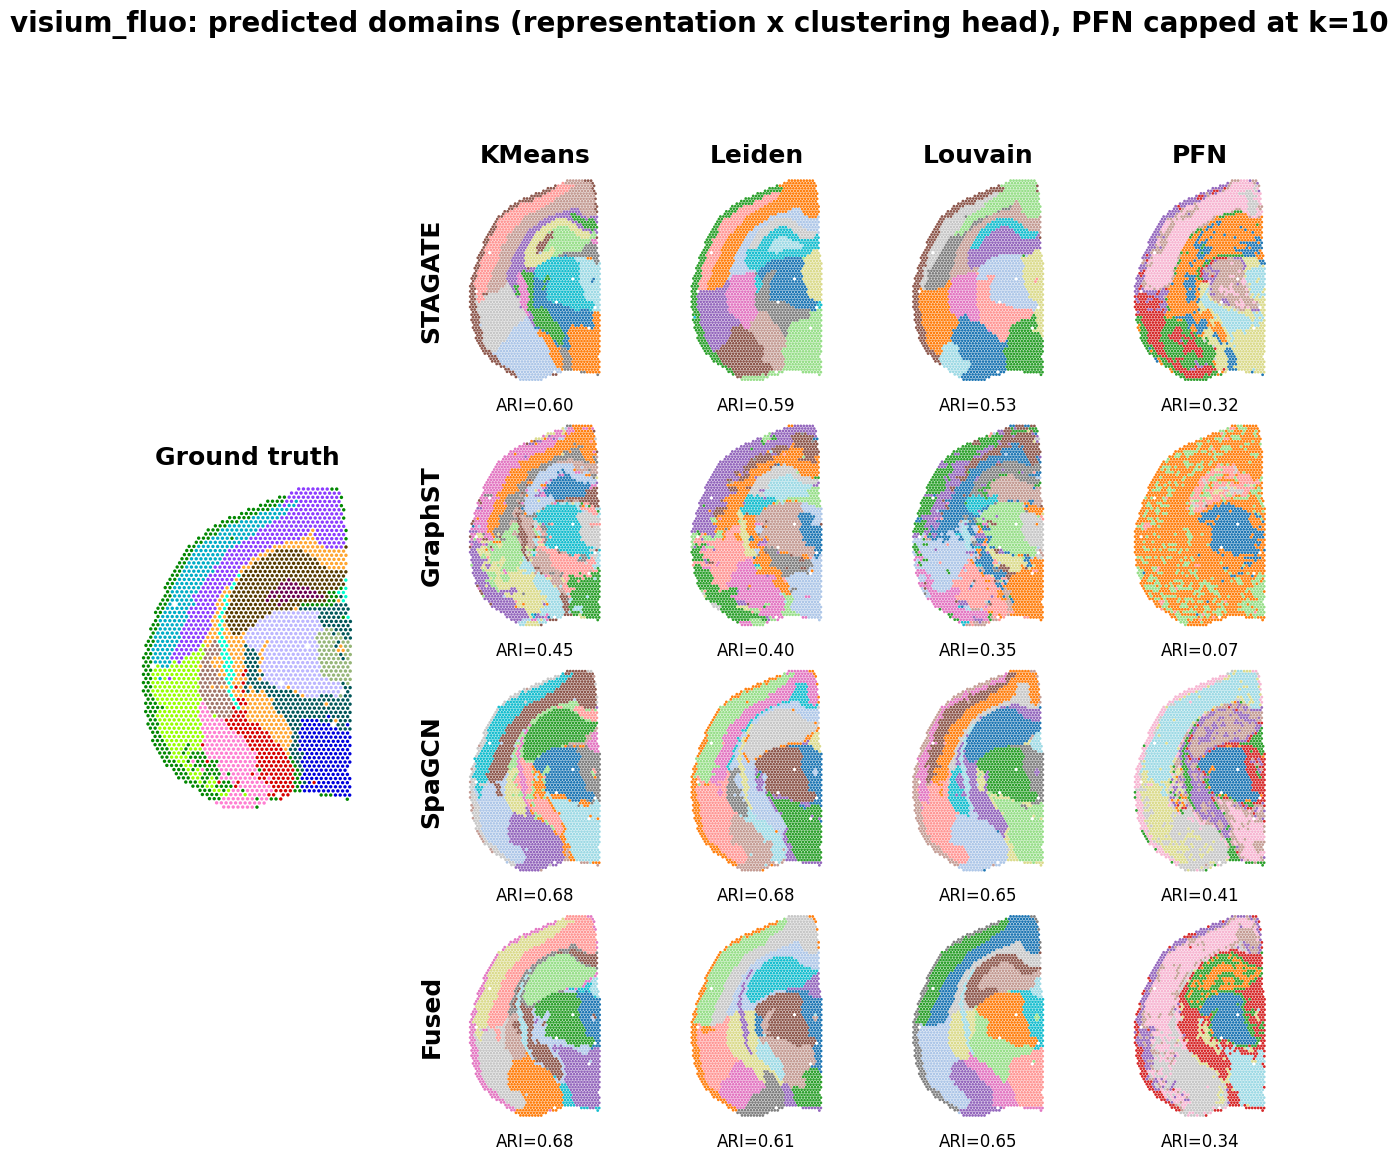

Saved -> experiment_test_plots/vis_visium_fluo.png


In [11]:
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.colors import ListedColormap
import colorcet as cc

TITLE_FS, LABEL_FS, SUP_FS, ARI_FS = 18, 18, 20, 12


def visualize_section(sec, path):
    ad = sc.read_h5ad(path)
    ad = ad[ad.obs["in_tissue"] == 1].copy()
    gt_ = ad.obs["cluster"].astype(str)
    k_ = gt_.nunique()
    k_pfn_ = min(k_, PFN_BUCKETS)
    co = np.asarray(ad.obsm["spatial"])
    gc = gt_.astype("category").cat.codes.to_numpy()

    embs = {m: np.load(f"{EMB_DIR}/{sec}_{m}_embedding.npy") for m in ENCODERS}
    reps_ = {**embs, "Fused": fuse([embs["STAGATE"], embs["SpaGCN"]])}

    def predict(e_, head):
        if head == "KMeans":
            return cluster_kmeans(e_, k_)
        if head == "Leiden":
            return cluster_leiden(e_, k_, max_iter=12)
        if head == "Louvain":
            return cluster_louvain(e_, k_, max_iter=12)
        return run_pfn(pfn, prepare_for_pfn(e_), k_pfn_)

    def scatter(ax, labels, ground_truth=False):
        # Ground truth uses the saturated glasbey palette; predictions keep the default tab20.
        if ground_truth:
            uniq = np.unique(labels)
            idx = np.searchsorted(uniq, labels)
            cmap = ListedColormap(cc.glasbey[:len(uniq)])
            ax.scatter(co[:, 0], co[:, 1], c=idx, cmap=cmap, s=6, linewidths=0)
        else:
            ax.scatter(co[:, 0], co[:, 1], c=labels, cmap="tab20", s=4, linewidths=0)
        ax.set_aspect("equal")
        ax.invert_yaxis()
        ax.axis("off")

    names = list(reps_)
    nrows, ncols = len(names), len(HEADS_VIS)
    fig = plt.figure(figsize=(2.9 * (ncols + 1) + 0.6, 3.1 * nrows))
    gsp = GridSpec(nrows, ncols + 2, figure=fig,
                   width_ratios=[1.1, 0.2] + [1] * ncols, wspace=0.08, hspace=0.12)

    axg = fig.add_subplot(gsp[:, 0])
    scatter(axg, gc, ground_truth=True)
    axg.set_title("Ground truth", fontsize=TITLE_FS, fontweight="bold")

    for i, name in enumerate(names):
        for j, head in enumerate(HEADS_VIS):
            ax = fig.add_subplot(gsp[i, j + 2])
            pred = predict(reps_[name], head)
            scatter(ax, pred)
            ax.text(0.5, -0.03, f"ARI={adjusted_rand_score(gt_, pred):.2f}",
                    transform=ax.transAxes, ha="center", va="top", fontsize=ARI_FS)
            if i == 0:
                ax.set_title(head, fontsize=TITLE_FS, fontweight="bold")
            if j == 0:
                ax.text(-0.14, 0.5, name, transform=ax.transAxes, rotation=90,
                        ha="right", va="center", fontsize=LABEL_FS, fontweight="bold")

    fig.suptitle(f"{sec}: predicted domains (representation x clustering head), PFN capped at k={k_pfn_}",
                 fontsize=SUP_FS, fontweight="bold", y=1.01)
    fig.savefig(f"experiment_test_plots/vis_{sec}.png", dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved -> experiment_test_plots/vis_{sec}.png")


visualize_section("visium_fluo", SQUIDPY_SECTIONS["visium_fluo"])